# 10 · Dispersive waves and spectral methods

Dispersive equations - Korteweg-de Vries, nonlinear Schrodinger - have solutions that stay smooth and
periodic domains that make Fourier spectral differentiation natural: multiply the Fourier coefficients by
(ik)ᵐ and the spatial error is exponentially small. The price is stiffness of a new kind: the spectral u_xxx has
eigenvalues up to (πn/L)³ on the imaginary axis, so explicit steps shrink like Δx³. This notebook propagates
solitons with spectral accuracy, collides two of them, checks the invariants of KdV and NLS, and shows what
aliasing does.

**What you will learn**
- differentiate periodic functions spectrally and know the accuracy it buys
- recognise the n^3 stiffness of dispersive operators
- check soliton solutions and conserved quantities
- diagnose aliasing and apply the 2/3 rule

**Before you start:** notebook 09 of engnumeric (the FFT) helps  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere engmolines is missing): install it from GitHub
    import engmolines
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engmolines"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engmolines import problems as pr, integrators as ti, analysis, stiffness, spectral
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Spectral differentiation

In [2]:
x = spectral.grid(0, 2 * np.pi, 32)
u = np.exp(np.sin(x))
for order in (1, 2, 3):
    exact = {1: np.cos(x) * u, 2: (np.cos(x) ** 2 - np.sin(x)) * u, 3: (np.cos(x) ** 3 - 3 * np.sin(x) * np.cos(x) - np.cos(x)) * u}[order]
    print(f"derivative {order} of exp(sin x) with 32 points: max error {np.max(np.abs(spectral.derivative(u, 2 * np.pi, order) - exact)):.1e}")
for n in (64, 128, 256):
    print(f"n = {n}, L = 40: spectral u_xxx has |lambda|max = {spectral.max_eigenvalue(n, 40, 3):.0f} -> RK4 step {2.8 / spectral.max_eigenvalue(n, 40, 3):.1e}")

derivative 1 of exp(sin x) with 32 points: max error 2.9e-15
derivative 2 of exp(sin x) with 32 points: max error 3.1e-14
derivative 3 of exp(sin x) with 32 points: max error 4.0e-13
n = 64, L = 40: spectral u_xxx has |lambda|max = 127 -> RK4 step 2.2e-02
n = 128, L = 40: spectral u_xxx has |lambda|max = 1016 -> RK4 step 2.8e-03
n = 256, L = 40: spectral u_xxx has |lambda|max = 8128 -> RK4 step 3.4e-04


Thirteen digits from 32 points - against two or three for finite differences - is why dispersive problems
are solved spectrally. The eigenvalues of the spectral third derivative grow like n³: doubling the resolution
divides the explicit step by eight. (Implicit treatment of the linear u_xxx term, an "exponential integrator"
or integrating factor, is the standard remedy; here the adaptive explicit solver is kept for clarity.)

## A KdV soliton

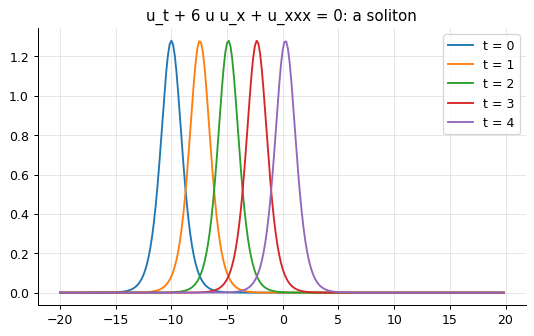

after t = 4: error vs 2 kappa^2 sech^2(kappa(x - 4 kappa^2 t - x0)) = 3.4e-08; 30172 steps (mean h 1.3e-04)


In [3]:
p = pr.kdv_soliton(kappa=0.8)
s = p.solve("dopri", rtol=1e-8, atol=1e-10, n_out=4)
for t, y in zip(s.t, s.y):
    plt.plot(p.x, y, label=f"t = {t:.0f}")
plt.legend(); plt.title("u_t + 6 u u_x + u_xxx = 0: a soliton"); plt.show()
print(f"after t = 4: error vs 2 kappa^2 sech^2(kappa(x - 4 kappa^2 t - x0)) = {p.error(s):.1e}; {s.steps} steps (mean h {np.mean(s.extra['h']):.1e})")

The soliton 2κ² sech²(κ(x − 4κ²t)) travels at 4κ² without changing shape: nonlinear steepening and dispersive
spreading balance exactly. The method of lines with spectral space and Dormand-Prince time reproduces it to
10⁻⁸ after four time units. Its mean step of 10⁻⁴ is below even the stability limit of 3×10⁻⁴, because the
tolerance of 10⁻⁸ on a problem with frequencies up to 8000 demands it: here accuracy, not stability, sets the
step.

## Two solitons collide

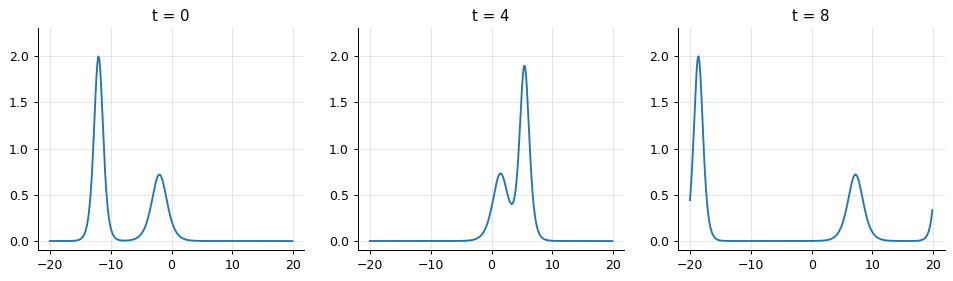

mass drift 2.3e-14, momentum drift 6.0e-14; peaks after the collision 1.9994 (2 k1^2 = 2.0)


In [4]:
p = pr.kdv_two_solitons(k1=1.0, k2=0.6)
s = p.solve("dopri", rtol=1e-8, atol=1e-10, n_out=8)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, i in zip(axes, (0, 4, 8)):
    ax.plot(p.x, s.y[i]); ax.set_title(f"t = {s.t[i]:.0f}"); ax.set_ylim(-0.1, 2.3)
plt.show()
mass = analysis.conservation(p.grid, s.y); mom = np.array([p.grid.integrate(y**2) for y in s.y])
print(f"mass drift {np.ptp(mass):.1e}, momentum drift {np.ptp(mom):.1e}; peaks after the collision {np.sort(s.y[-1])[-1]:.4f} (2 k1^2 = 2.0)")

The taller, faster soliton overtakes the shorter one; during the overlap the profile is not a sum of the two,
yet both emerge unchanged except for a phase shift - the defining property of solitons. The integrals of u and
u² (two of KdV's infinitely many invariants) are conserved to 10⁻¹⁴: the spectral operator is exactly
antisymmetric, and the adaptive integrator's error is far below the invariants' sensitivity.

## Nonlinear Schrodinger: a complex field

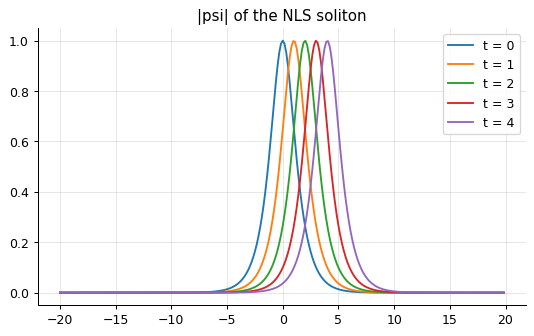

error vs the exact soliton 2.3e-07; mass integral |psi|^2 drift -2.0e-14


In [5]:
p = pr.nls_soliton(v=0.5)
s = p.solve("dopri", rtol=1e-8, atol=1e-10, n_out=4)
n = 256
for t, y in zip(s.t, s.y):
    plt.plot(p.x, np.abs(y[:n] + 1j * y[n:]), label=f"t = {t:.0f}")
plt.legend(); plt.title("|psi| of the NLS soliton"); plt.show()
psi = s.y[-1][:n] + 1j * s.y[-1][n:]
print(f"error vs the exact soliton {p.error(s):.1e}; mass integral |psi|^2 drift {p.grid.integrate(np.abs(psi)**2) - p.params['mass']:+.1e}")

The complex field is split into real and imaginary parts to form a real ODE system; the exact soliton
sech(x − 2vt) e^{i(vx + (1 − v²)t)} is reproduced to 10⁻⁷, and the mass ∫|ψ|² is conserved.

## Aliasing

In [6]:
x = spectral.grid(0, 2 * np.pi, 32)
u = np.cos(12 * x)
prod = u * u                                                   # contains the mode 24 > n/2 = 16: it aliases to mode 8
coeffs = np.abs(np.fft.fft(prod)) / 32
print(f"u = cos(12x) on 32 points; u^2 should have modes 0 and 24, but the FFT of the product shows mode {np.argmax(coeffs[1:16]) + 1} with amplitude {coeffs[8]:.2f} (aliased from 24)")
ud = spectral.dealias(u)
print(f"after the 2/3 rule (modes above {32 // 3} removed) the product of dealiased fields cannot alias into the kept range: cos(12x) itself is removed ({np.max(np.abs(ud)):.1e})")

u = cos(12x) on 32 points; u^2 should have modes 0 and 24, but the FFT of the product shows mode 8 with amplitude 0.25 (aliased from 24)
after the 2/3 rule (modes above 10 removed) the product of dealiased fields cannot alias into the kept range: cos(12x) itself is removed (6.4e-15)


A product of two resolved modes can produce a wavenumber the grid cannot represent, which folds back onto a
low mode - aliasing - and in a nonlinear simulation feeds energy into the wrong scales. The 2/3 rule keeps only
modes below n/3, so that no product of kept modes aliases into the kept range. The KdV runs above were
resolved well enough (the solitons' spectra decay exponentially) that aliasing was invisible; for turbulent or
under-resolved fields it is not.

## Inside the algorithm: a spectral derivative by hand

In [7]:
n, L = 64, 40.0
k = 2 * np.pi * np.fft.fftfreq(n, L / n)
xx = spectral.grid(-L / 2, L / 2, n); f = 1 / np.cosh(xx) ** 2
d3_hand = np.fft.ifft((1j * k) ** 3 * np.fft.fft(f)).real
print("u_xxx of sech^2 by hand vs library:", np.max(np.abs(d3_hand - spectral.derivative(f, L, 3))))

u_xxx of sech^2 by hand vs library: 0.0


## Exercises
1. Integrate the KdV soliton with an integrating factor: write v = exp(-D3 t) u in Fourier space so that the linear term disappears, and integrate only the nonlinear term explicitly. How much larger can the step be?
2. Give the NLS soliton twice the amplitude (2 sech(2x) e^(4it) is also a soliton). Measure the step the adaptive integrator needs and explain it from the frequency 4.
3. **Implement it yourself:** write the KdV right-hand side with the 2/3 dealiasing applied to the product u u_x, and compare the two-soliton invariants with and without it at n = 64 (under-resolved).